# 03 – Who is over- and underpaid? (2024–2025)

We score every 2024–2025 player-season with the Phase 3 XGBoost model: *given this production, what share of the
cap would the market pay?* Then:

**contract gap = actual APY % of cap − predicted APY % of cap** (positive = paid more than the production earns)

Converted to dollars with each season's salary cap.

### Labeling rules (veterans only)
Phase 3 showed the model **shrinks extreme salaries toward the average**: stars are under-predicted and minimum
deals over-predicted. So a raw gap would always call stars overpaid. Section 3 first applies the rule as specified
(percentile *within position*), shows that it still flags mostly the highest-paid players, and then refines it.
Final rules:
- **Overpaid**: gap in the top 15% *within the player's position and pay tier* (thirds of veteran pay at that
  position) **and** at least \$2.5M (about 1% of the cap)
- **Underpaid**: gap in the bottom 15% within position and pay tier **and** at least \$2.5M below the prediction
- **Injury-shortened**: would be Overpaid, but played fewer than 10 games. Missing games isn't the same as
  underperforming per game, so these players are reported separately.
- **Limited sample**: would be Underpaid, but played fewer than 10 games (usually a backup's short spot-start run)
- **Fair**: everyone else

Rookie-contract players aren't labeled. Their pay is set by draft slot, so we report their **surplus**
(predicted − actual, in \$) instead.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import mean_absolute_error

from src.model import (MIN_GAMES, POSITIONS, TAIL_PCT, TARGET, apply_contract_overrides, assign_labels,
                       build_features, implied_salary_cap, load_player_season, pay_tiers, train_model)

# v1 exports live in exports/v1/; exports/ itself holds the current (v2) model's files
FIG_DIR, EXPORT_DIR = ROOT / "docs" / "figures", ROOT / "exports" / "v1"
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 2)

# Labeling thresholds (TAIL_PCT = 15%, MIN_GAP_MUSD = $2.5M, MIN_GAMES = 10) live in src/model.py

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.axisbelow": True,
})

## 1. Model, overrides and salary cap

**Daniel Jones 2024 is corrected, not excluded.** The SQL rule picked a Vikings deal (0.4% of cap) signed *after*
the Giants released him, but all 10 of his 2024 games were played on his 2023 Giants contract (17.8% of cap).
That season is real and informative (benched, then released), so we keep it with the correct contract.
The correction lives in `src/model.py` (`CONTRACT_OVERRIDES`) with its reason.

The model is refit from the Phase 3 settings. It's only trained on 2019–2023 veterans, so the override (a 2024 row)
can't affect it, and we check that it reproduces the Phase 3 test score exactly.

In [2]:
ps = apply_contract_overrides(load_player_season())
print("overrides applied:")
print(ps.loc[ps["override_reason"].notna(), ["player_name", "season", "team", "apy", TARGET, "override_reason"]].to_string(index=False))

model = train_model(ps)
check = ps[(ps["season"] >= 2024) & ~ps["is_rookie_contract"] & ps["override_reason"].isna()]
check_mae = 100 * mean_absolute_error(check[TARGET], model.predict(build_features(check)))
print(f"\nreproducibility: test MAE without the overridden row = {check_mae:.4f} pp")

cap = implied_salary_cap([2024, 2025])
print("\nimplied salary cap ($M):", cap.round(1).to_dict())

overrides applied:
 player_name  season team  apy  apy_cap_pct                                                                                                                                           override_reason
Daniel Jones    2024  NYG 40.0         0.18 Played all 10 games for NYG on his 2023 Giants deal (4 yrs, $40M APY); the 2024 Vikings deal (0.4% of cap) was signed after NYG released him in November.



reproducibility: test MAE without the overridden row = 1.9978 pp

implied salary cap ($M): {2024: 255.4, 2025: 278.8}


## 2. Score 2024–2025

In [3]:
scored = ps[ps["season"].isin([2024, 2025])].copy()
scored["predicted"] = model.predict(build_features(scored))
scored["season_cap_musd"] = scored["season"].map(cap)

# Everything below in two units: percentage points of cap, and $M at that season's cap
scored["actual_pct"] = 100 * scored[TARGET]
scored["predicted_pct"] = 100 * scored["predicted"]
scored["gap_pp"] = scored["actual_pct"] - scored["predicted_pct"]
scored["actual_musd"] = scored[TARGET] * scored["season_cap_musd"]
scored["predicted_musd"] = scored["predicted"] * scored["season_cap_musd"]
scored["gap_musd"] = scored["actual_musd"] - scored["predicted_musd"]

print(f"{len(scored):,} player-seasons scored: {(~scored['is_rookie_contract']).sum()} veteran, "
      f"{scored['is_rookie_contract'].sum()} rookie-contract")

696 player-seasons scored: 413 veteran, 283 rookie-contract


## 3. Labels

### 3a. First attempt: the rule as specified (percentile within position)

In [4]:
vet = ~scored["is_rookie_contract"]
# Pay tier: thirds of actual pay among veterans at the same position (both seasons pooled)
scored["pay_tier"] = pay_tiers(scored)
# assign_labels (src/model.py): top/bottom 15% of the gap within the given groups, plus the $2.5M minimum

def tier_check(labels: pd.Series) -> pd.DataFrame:
    """% of veterans in each pay tier that got each label. An unbiased rule flags all tiers similarly."""
    t = pd.crosstab(scored.loc[vet, "pay_tier"], labels[vet], normalize="index") * 100
    return t.reindex(index=["low", "mid", "high"]).reindex(
        columns=["Overpaid", "Injury-shortened", "Fair", "Limited sample", "Underpaid"], fill_value=0).round(1)

label_v1, _ = assign_labels(scored, "gap_pp", "gap_musd", ["position"], min_games=MIN_GAMES)
print("First attempt, % of veterans per label by pay tier:")
tier_check(label_v1)

First attempt, % of veterans per label by pay tier:


col_0,Overpaid,Injury-shortened,Fair,Limited sample,Underpaid
pay_tier,,,,,
low,0.0,0.0,82.0,0,18.0
mid,2.2,0.0,81.6,0,16.2
high,36.2,5.1,49.3,0,9.4


In [5]:
# Who the first attempt flags at the extremes
v1 = scored.assign(label_v1=label_v1)
show = ["player_name", "position", "season", "games_played", "total_epa", "actual_pct", "predicted_pct", "gap_musd", "label_v1"]
pd.concat([v1[v1["label_v1"] == "Overpaid"].nlargest(6, "gap_musd"),
           v1[v1["label_v1"] == "Underpaid"].nsmallest(6, "gap_musd")])[show]

,player_name,position,season,games_played,total_epa,actual_pct,predicted_pct,gap_musd,label_v1
2121,Lamar Jackson,QB,2025,13,30.20,23.1,9.38,38.25,Overpaid
1899,Trevor Lawrence,QB,2024,10,4.66,21.5,7.77,35.07,Overpaid
2058,Kirk Cousins,QB,2025,10,-5.61,17.6,5.42,33.96,Overpaid
1809,Josh Allen,QB,2024,17,187.66,23.6,10.86,32.53,Overpaid
1855,Jordan Love,QB,2024,15,60.22,21.5,12.43,23.17,Overpaid
1878,Jaylen Waddle,WR,2024,15,37.91,11.1,3.38,19.72,Overpaid
1711,Russell Wilson,QB,2024,11,-2.03,0.5,18.24,-45.30,Underpaid
2053,Aaron Rodgers,QB,2025,16,18.54,4.9,16.21,-31.54,Underpaid
1810,Sam Darnold,QB,2024,17,42.06,3.9,16.18,-31.37,Underpaid
2080,Carson Wentz,QB,2025,5,5.84,0.5,9.13,-24.06,Underpaid


**This fails the eye test.** Josh Allen's 2024 MVP season (188 total EPA) is labeled Overpaid, and 36.2% of the
highest-paid third of veterans are Overpaid vs 0% of the lowest-paid third. Ranking within position isn't enough,
because the model's shrinkage happens *within* each position too: the highest-paid players always have the biggest
positive gaps. And the Underpaid side is full of short spot-starts with poor production (Tyler Huntley: 5 games,
−19.5 EPA, "underpaid by \$14.7M"), because the model values a starter's *role* (snap %, dropbacks).

### 3b. Final rule: percentile within position **and pay tier**, 10-game minimum on both sides
Comparing a player with others **paid like him** asks the right question ("among QBs paid 20%+ of the cap, whose
production falls furthest short?") and cancels the shrinkage that's built into the model.

In [6]:
scored["label"], scored["gap_pctile"] = assign_labels(scored, "gap_pp", "gap_musd", ["position", "pay_tier"],
                                                     min_games=MIN_GAMES, min_games_for_underpaid=True)
print("Final rule, % of veterans per label by pay tier:")
tier_check(scored["label"])

Final rule, % of veterans per label by pay tier:


label,Overpaid,Injury-shortened,Fair,Limited sample,Underpaid
pay_tier,,,,,
low,0.0,0.7,84.9,3.6,10.8
mid,12.5,0.0,73.5,0.7,13.2
high,14.5,2.9,73.9,0.0,8.7


In [7]:
label_order = ["Overpaid", "Injury-shortened", "Fair", "Limited sample", "Underpaid", "Rookie contract"]
pd.crosstab(scored["label"], scored["position"], margins=True, margins_name="total").reindex(label_order + ["total"])[POSITIONS + ["total"]]

position,QB,RB,WR,TE,total
label,,,,,
Overpaid,6,6,14,11,37
Injury-shortened,3,0,2,0,5
Fair,48,68,128,76,320
Limited sample,1,0,4,1,6
Underpaid,5,12,15,13,45
Rookie contract,30,58,124,71,283
total,93,144,287,172,696


In [8]:
# How labels moved from the first attempt to the final rule (veterans)
pd.crosstab(label_v1[vet].rename("first attempt"), scored.loc[vet, "label"].rename("final"))

final,Fair,Injury-shortened,Limited sample,Overpaid,Underpaid
first attempt,,,,,
Fair,271,1,0,14,7
Injury-shortened,3,4,0,0,0
Overpaid,30,0,0,23,0
Underpaid,16,0,6,0,38


In [9]:
# What the thresholds mean: the gap ($M) needed to be flagged in each position and pay tier
cut = scored[vet].groupby(["position", "pay_tier"])["gap_musd"].quantile([TAIL_PCT, 1 - TAIL_PCT]).unstack()
cut.columns = ["bottom 15% cut ($M)", "top 15% cut ($M)"]
tier_range = scored[vet].groupby(["position", "pay_tier"])["actual_pct"].agg(["min", "max"]).rename(
    columns={"min": "tier min % cap", "max": "tier max % cap"})
cut.join(tier_range).reindex(pd.MultiIndex.from_product([POSITIONS, ["low", "mid", "high"]])).round(2)

bottom 15% cut ($M)  top 15% cut ($M)  tier min % cap  tier max % cap
QB low                -16.44             -3.03             0.4             4.9
   mid                -11.24             14.78             4.9            20.8
   high                 6.26             35.20            20.8            24.5
RB low                 -3.86             -0.40             0.3             0.6
   mid                 -2.75              1.99             0.7             2.2
   high                -5.22              3.73             2.2             7.4
WR low                 -4.65             -0.28             0.1             0.8
   mid                 -7.41              2.15             0.8             5.4
   high                 1.23             12.02             5.4            14.4
TE low                 -2.49             -0.10             0.4             1.0
   mid                 -2.03              2.67             1.0             2.9
   high                -3.34              7.45             3.0             7.8

## 4. The lists

In [10]:
cols = ["player_name", "position", "season", "team", "age", "games_played", "total_epa", "epa_per_play",
        "snap_pct", "actual_pct", "predicted_pct", "actual_musd", "predicted_musd", "gap_musd"]

print("TOP 15 OVERPAID VETERANS (actual − predicted, $M)")
overpaid = scored[scored["label"] == "Overpaid"].nlargest(15, "gap_musd")[cols]
overpaid

TOP 15 OVERPAID VETERANS (actual − predicted, $M)


,player_name,position,season,team,age,games_played,total_epa,epa_per_play,snap_pct,actual_pct,predicted_pct,actual_musd,predicted_musd,gap_musd
2121,Lamar Jackson,QB,2025,BAL,28.65,13,30.20,7.65e-02,0.93,23.1,9.38,64.41,26.16,38.25
1899,Trevor Lawrence,QB,2024,JAX,24.91,10,4.66,1.44e-02,0.89,21.5,7.77,54.91,19.83,35.07
2058,Kirk Cousins,QB,2025,ATL,37.03,10,-5.61,-1.96e-02,0.86,17.6,5.42,49.08,15.12,33.96
1878,Jaylen Waddle,WR,2024,MIA,25.77,15,37.91,4.36e-01,0.78,11.1,3.38,28.35,8.63,19.72
2128,Josh Allen,QB,2025,BUF,29.28,17,113.95,1.92e-01,0.91,19.7,12.75,54.93,35.56,19.38
2119,Christian Kirk,WR,2025,HOU,28.79,13,-20.22,-3.89e-01,0.49,8.6,2.41,23.98,6.73,17.25
1709,Matthew Stafford,QB,2024,LA,36.57,16,40.89,7.32e-02,1.00,19.2,12.46,49.04,31.83,17.21
2176,CeeDee Lamb,WR,2025,DAL,26.40,14,28.74,2.44e-01,0.73,13.3,7.49,37.09,20.89,16.20
2123,DJ Moore,WR,2025,CHI,28.38,17,21.66,2.14e-01,0.85,10.8,5.25,30.12,14.63,15.49
1706,Aaron Rodgers,QB,2024,NYJ,40.75,17,3.76,5.87e-03,0.97,16.7,10.91,42.65,27.87,14.78


In [11]:
print("TOP 15 UNDERPAID VETERANS")
underpaid = scored[scored["label"] == "Underpaid"].nsmallest(15, "gap_musd")[cols]
underpaid

TOP 15 UNDERPAID VETERANS


,player_name,position,season,team,age,games_played,total_epa,epa_per_play,snap_pct,actual_pct,predicted_pct,actual_musd,predicted_musd,gap_musd
1711,Russell Wilson,QB,2024,PIT,35.76,11,-2.03,-5.10e-03,0.98,0.5,18.24,1.28,46.58,-45.30
2053,Aaron Rodgers,QB,2025,PIT,41.75,16,18.54,3.46e-02,0.96,4.9,16.21,13.66,45.20,-31.54
1810,Sam Darnold,QB,2024,MIN,27.24,17,42.06,6.60e-02,0.99,3.9,16.18,9.96,41.33,-31.37
1808,Baker Mayfield,QB,2024,TB,29.39,17,120.94,1.82e-01,0.98,13.1,19.77,33.46,50.49,-17.03
2156,Daniel Jones,QB,2025,IND,28.27,13,78.68,1.78e-01,0.91,5.0,9.51,13.94,26.52,-12.57
2169,Jauan Jennings,WR,2025,SF,28.15,15,-1.43,-1.59e-02,0.82,2.3,6.78,6.41,18.91,-12.49
1843,Rico Dowdle,RB,2024,DAL,26.22,16,-5.27,-1.85e-02,0.57,0.5,5.34,1.28,13.63,-12.36
2061,Zach Ertz,TE,2025,WAS,34.81,13,10.66,1.48e-01,0.67,2.2,6.00,6.13,16.72,-10.59
2258,Christian Watson,WR,2025,GB,26.31,10,32.09,5.73e-01,0.68,3.9,7.59,10.87,21.16,-10.29
1793,Ray-Ray McCloud,WR,2024,ATL,27.88,17,7.99,8.24e-02,0.86,1.0,4.94,2.55,12.62,-10.07


In [12]:
print("TOP 15 ROOKIE-CONTRACT SURPLUS (predicted − actual, $M)")
rookies = scored[scored["label"] == "Rookie contract"].assign(surplus_musd=lambda d: -d["gap_musd"])
top_rookies = rookies.nlargest(15, "surplus_musd")[cols[:-1] + ["surplus_musd"]]
top_rookies

TOP 15 ROOKIE-CONTRACT SURPLUS (predicted − actual, $M)


,player_name,position,season,team,age,games_played,total_epa,epa_per_play,snap_pct,actual_pct,predicted_pct,actual_musd,predicted_musd,surplus_musd
2327,Bo Nix,QB,2025,DEN,25.52,17,72.11,0.10,1.00,1.8,20.06,5.02,55.93,50.91
2335,Drake Maye,QB,2025,NE,23.01,17,186.33,0.30,0.96,3.6,18.94,10.04,52.82,42.78
1941,Brock Purdy,QB,2024,SF,24.68,15,105.15,0.19,0.99,0.4,16.13,1.02,41.20,40.18
2028,Bo Nix,QB,2024,DEN,24.52,17,54.34,0.08,0.99,1.8,14.43,4.60,36.85,32.26
2346,Michael Penix Jr.,QB,2025,ATL,25.32,9,8.14,0.03,0.93,2.2,13.32,6.13,37.16,31.02
2306,Bryce Young,QB,2025,CAR,24.10,16,-12.08,-0.02,0.96,4.2,14.38,11.71,40.09,28.38
2046,Jayden Daniels,QB,2024,WAS,23.70,17,121.77,0.18,0.91,3.7,13.03,9.45,33.29,23.84
2222,Chris Olave,WR,2025,NO,25.18,16,30.78,0.19,0.84,2.3,10.28,6.41,28.68,22.26
2347,Caleb Williams,QB,2025,CHI,23.79,17,60.92,0.09,0.99,3.9,11.75,10.87,32.77,21.89
2298,Zay Flowers,WR,2025,BAL,24.97,17,50.10,0.39,0.87,1.6,9.37,4.46,26.13,21.67


In [13]:
print("INJURY-SHORTENED (would be Overpaid, but fewer than 10 games)")
scored[scored["label"] == "Injury-shortened"].sort_values("gap_musd", ascending=False)[cols]

INJURY-SHORTENED (would be Overpaid, but fewer than 10 games)


,player_name,position,season,team,age,games_played,total_epa,epa_per_play,snap_pct,actual_pct,predicted_pct,actual_musd,predicted_musd,gap_musd
2184,Joe Burrow,QB,2025,CIN,28.73,8,33.02,0.11,0.88,24.5,7.27,68.32,20.26,48.06
1761,Deshaun Watson,QB,2024,CLE,28.97,7,-64.44,-0.23,0.87,22.1,7.99,56.44,20.40,36.04
1854,Brandon Aiyuk,WR,2024,SF,26.46,7,12.81,0.27,0.76,11.7,6.20,29.88,15.83,14.05
2125,Calvin Ridley,WR,2025,TEN,30.70,7,12.22,0.34,0.58,9.0,4.22,25.10,11.75,13.34
2057,Russell Wilson,QB,2025,NYG,36.76,6,-16.95,-0.12,0.53,3.8,2.74,10.60,7.63,2.97


## 5. Eye test

The pay-tier check is in section 3. Here: the 20 highest-paid veteran seasons and their final labels.

In [14]:
# The 20 highest-paid veteran seasons
scored[vet].nlargest(20, "actual_pct")[["player_name", "position", "season", "team", "games_played", "total_epa",
                                         "actual_pct", "predicted_pct", "gap_musd", "label"]]

,player_name,position,season,team,games_played,total_epa,actual_pct,predicted_pct,gap_musd,label
1872,Joe Burrow,QB,2024,CIN,17,122.20,24.5,17.77,17.20,Fair
2184,Joe Burrow,QB,2025,CIN,8,33.02,24.5,7.27,48.06,Injury-shortened
1809,Josh Allen,QB,2024,BUF,17,187.66,23.6,10.86,32.53,Fair
1745,Dak Prescott,QB,2024,DAL,8,-12.88,23.5,11.69,30.17,Fair
2081,Dak Prescott,QB,2025,DAL,17,104.10,23.5,18.30,14.51,Fair
1862,Justin Herbert,QB,2024,LAC,17,79.70,23.4,20.95,6.26,Fair
2175,Justin Herbert,QB,2025,LAC,16,32.08,23.4,17.67,15.97,Fair
1801,Lamar Jackson,QB,2024,BAL,17,191.27,23.1,18.05,12.90,Fair
2121,Lamar Jackson,QB,2025,BAL,13,30.20,23.1,9.38,38.25,Overpaid
1772,Patrick Mahomes,QB,2024,KC,16,102.91,22.7,17.66,12.88,Fair


## 6. Team totals ($M)

- **overpaid_musd**: dollars paid above the prediction, summed over the team's Overpaid veterans
- **underpaid_surplus_musd**: dollars of production *above* pay, summed over Underpaid veterans
- **rookie_surplus_musd**: net surplus of all rookie-contract players (busts count as negative)
- **net_value_musd** = underpaid surplus + rookie surplus − overpaid

Only QB/RB/WR/TE with 200+ snaps are included, and a traded player counts for the team he played the most snaps for.

In [15]:
def team_totals(d: pd.DataFrame) -> pd.Series:
    is_ = lambda lab: d["label"] == lab
    return pd.Series({
        "overpaid_musd": d.loc[is_("Overpaid"), "gap_musd"].sum(),
        "n_overpaid": is_("Overpaid").sum(),
        "injury_shortened_musd": d.loc[is_("Injury-shortened"), "gap_musd"].sum(),
        "n_injury_shortened": is_("Injury-shortened").sum(),
        "underpaid_surplus_musd": -d.loc[is_("Underpaid"), "gap_musd"].sum(),
        "n_underpaid": is_("Underpaid").sum(),
        "rookie_surplus_musd": -d.loc[is_("Rookie contract"), "gap_musd"].sum(),
        "n_rookie": is_("Rookie contract").sum(),
    })

# "Limited sample" players aren't counted: their gap rests on fewer than 10 games
team_season = scored.groupby(["team", "season"]).apply(team_totals, include_groups=False).reset_index()
team_season["net_value_musd"] = (team_season["underpaid_surplus_musd"] + team_season["rookie_surplus_musd"]
                                 - team_season["overpaid_musd"])
count_cols = [c for c in team_season.columns if c.startswith("n_")]
money_cols = [c for c in team_season.columns if c.endswith("_musd")]
team_season[count_cols] = team_season[count_cols].astype(int)
team_season[money_cols] = team_season[money_cols] + 0.0   # turn -0.0 into 0.0

team_both = (team_season.drop(columns="season").groupby("team").sum()
             .sort_values("net_value_musd", ascending=False))
print("2024 + 2025 combined, ranked by net value")
team_both.round(1)

2024 + 2025 combined, ranked by net value


,overpaid_musd,n_overpaid,injury_shortened_musd,n_injury_shortened,underpaid_surplus_musd,n_underpaid,rookie_surplus_musd,n_rookie,net_value_musd
team,,,,,,,,,
DEN,0.0,0,0.0,0,8.5,2,92.1,10,100.6
PIT,12.6,2,0.0,0,83.1,3,17.6,9,88.0
SF,0.0,0,14.1,1,25.8,3,52.6,4,78.4
NO,4.9,1,0.0,0,21.8,3,58.1,7,75.0
TB,0.0,0,0.0,0,32.2,4,41.1,12,73.4
CAR,7.9,2,0.0,0,23.4,3,47.9,10,63.3
NYG,0.0,0,3.0,1,0.0,0,62.1,13,62.1
WAS,3.1,1,0.0,0,18.9,2,33.1,10,48.9
CIN,0.0,0,48.1,1,3.9,1,44.6,6,48.5


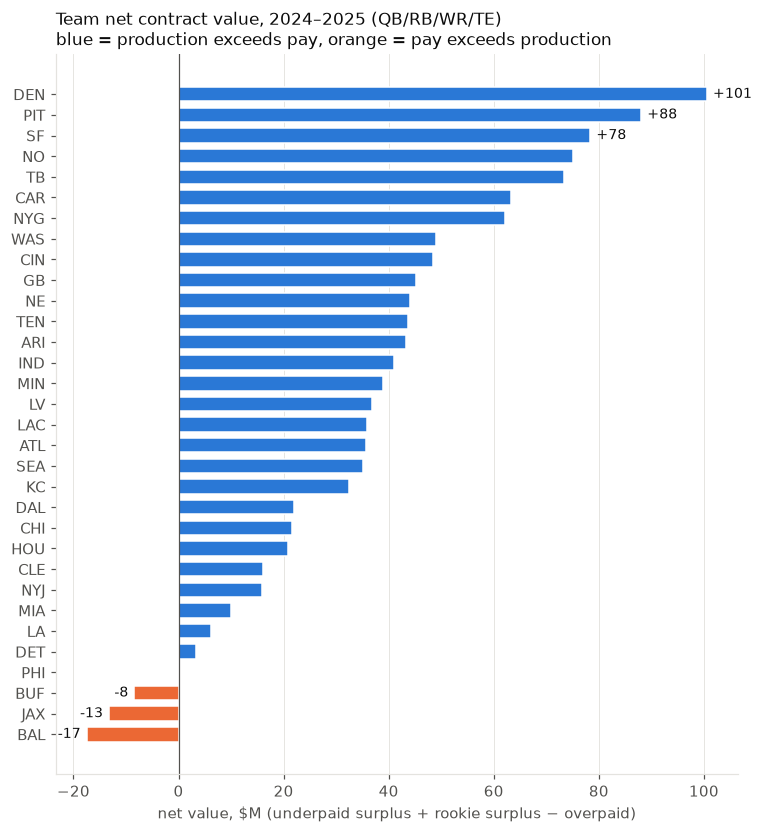

In [16]:
fig, ax = plt.subplots(figsize=(8, 8.5))
t = team_both["net_value_musd"].sort_values()
colors = np.where(t >= 0, BLUE, ORANGE)
ax.barh(t.index, t.values, color=colors, height=0.7, edgecolor="white", linewidth=1)
ax.axvline(0, color=MUTED, linewidth=0.8)
for name in list(t.index[:3]) + list(t.index[-3:]):   # label only the extremes
    v = t[name]
    ax.annotate(f"{v:+.0f}", (v, name), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                ha="left" if v >= 0 else "right", va="center", fontsize=9, color=INK)
ax.grid(axis="y", visible=False)
ax.set_xlabel("net value, $M (underpaid surplus + rookie surplus − overpaid)")
ax.set_title("Team net contract value, 2024–2025 (QB/RB/WR/TE)\nblue = production exceeds pay, orange = pay exceeds production",
             loc="left", fontsize=11)
fig.savefig(FIG_DIR / "team_net_value.png")
plt.show()

## 7. What production is missing? SHAP for three overpaid players

For the largest Overpaid gap at each of three positions: the waterfall shows which features pull the predicted
pay *down*, and a peer table compares the player with veterans at his position paid within ±25% of his cap %.

In [17]:
explainer = shap.TreeExplainer(model)
X_scored = build_features(scored)
sv = explainer(X_scored)
sv_pp = shap.Explanation(values=sv.values * 100, base_values=sv.base_values * 100,
                         data=X_scored.to_numpy(), feature_names=list(X_scored.columns))
pos_of = {i: k for k, i in enumerate(scored.index)}   # scored index -> SHAP row

# The largest Overpaid gap in each position, keeping the three positions with the biggest gaps
top_by_pos = scored[scored["label"] == "Overpaid"].sort_values("gap_musd", ascending=False).groupby("position").head(1)
examples = top_by_pos.head(3)
examples[["player_name", "position", "season", "team", "actual_pct", "predicted_pct", "gap_musd"]]

,player_name,position,season,team,actual_pct,predicted_pct,gap_musd
2121,Lamar Jackson,QB,2025,BAL,23.1,9.38,38.25
1878,Jaylen Waddle,WR,2024,MIA,11.1,3.38,19.72
2102,David Njoku,TE,2025,CLE,6.6,2.69,10.90


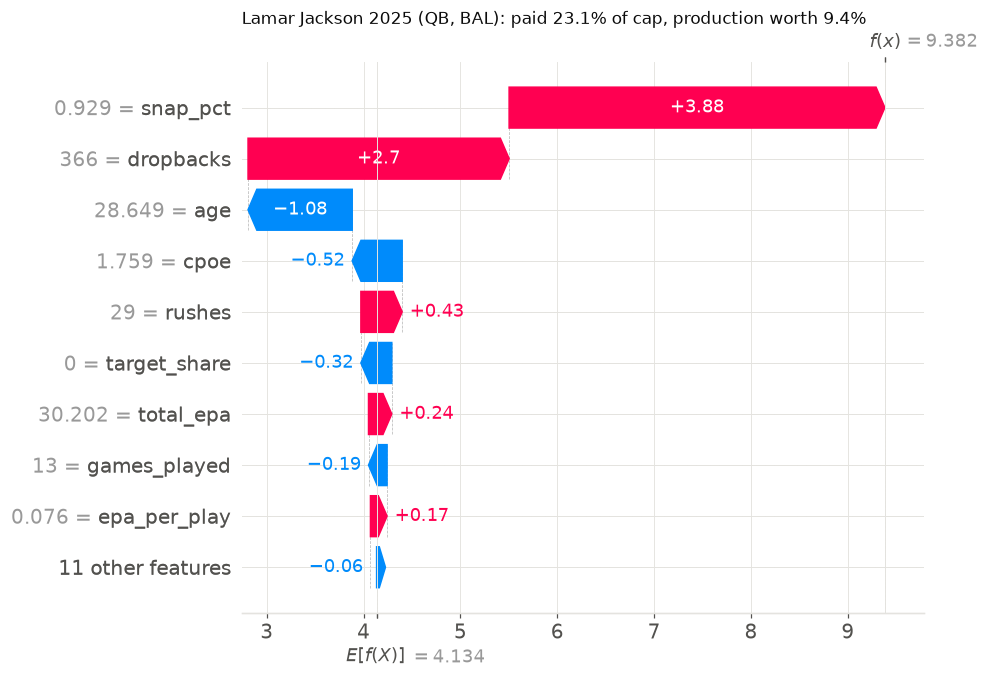

,Lamar Jackson 2025,peer median (n=29)
games_played,13.00,15.00
snap_pct,0.93,0.97
dropbacks,366.00,524.00
rushes,29.00,10.00
targets,0.00,0.00
target_share,0.00,0.00
total_epa,30.20,65.72
epa_per_play,0.08,0.13
success_rate,0.47,0.49
cpoe,1.76,1.95


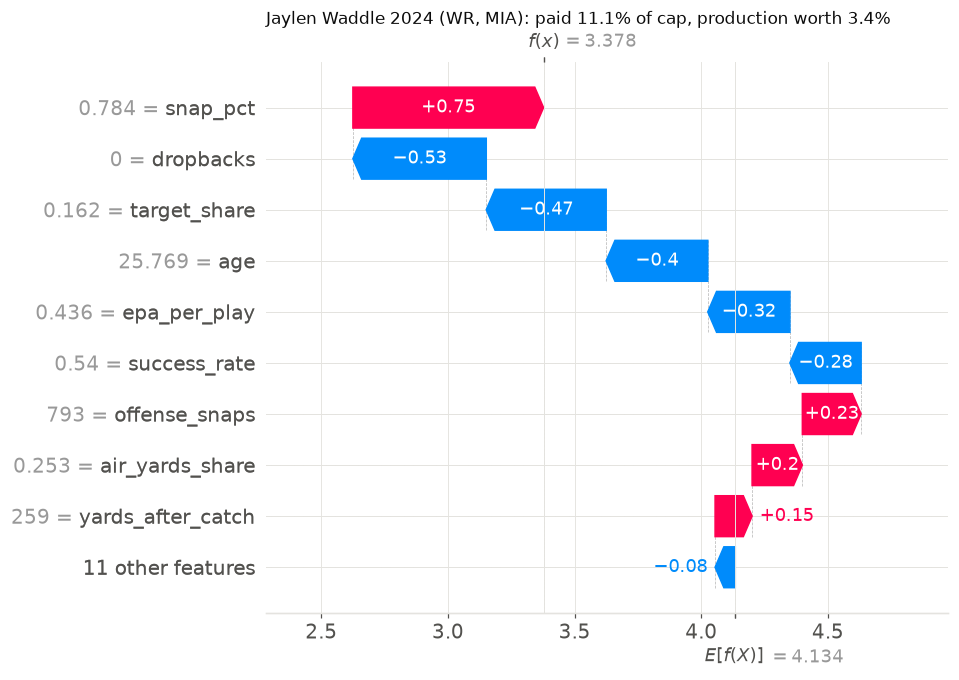

,Jaylen Waddle 2024,peer median (n=40)
games_played,15.00,15.00
snap_pct,0.78,0.82
rushes,4.00,1.00
targets,83.00,101.00
target_share,0.16,0.24
total_epa,37.91,24.83
epa_per_play,0.44,0.26
success_rate,0.54,0.51


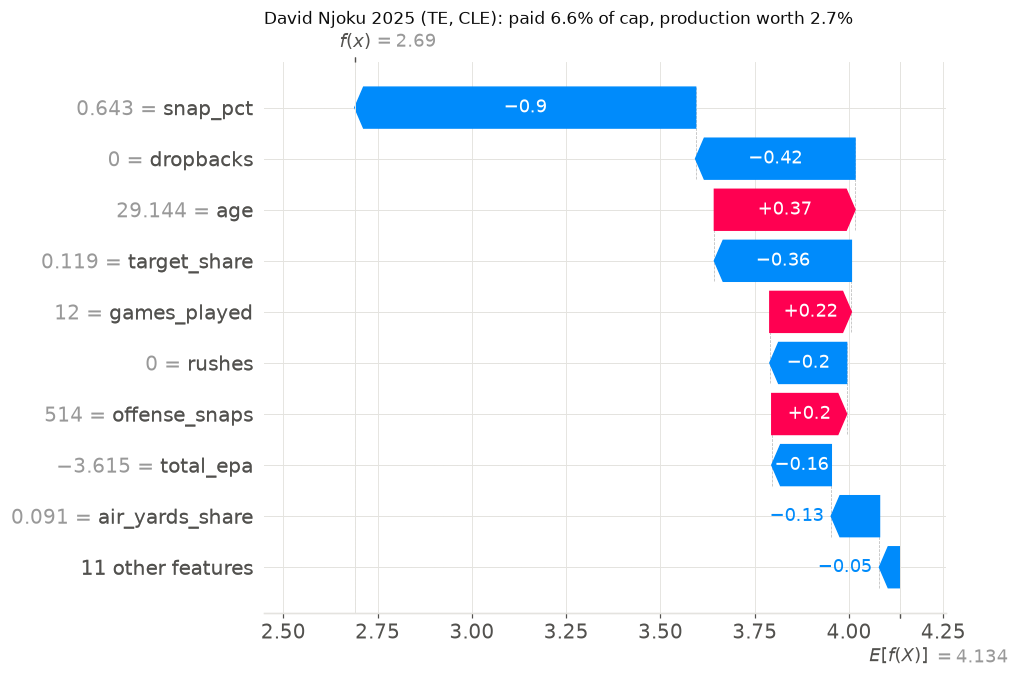

,David Njoku 2025,peer median (n=14)
games_played,12.00,15.00
snap_pct,0.64,0.77
rushes,0.00,0.00
targets,48.00,67.50
target_share,0.12,0.20
total_epa,-3.62,21.71
epa_per_play,-0.07,0.32
success_rate,0.48,0.57


In [18]:
key_stats = ["games_played", "snap_pct", "dropbacks", "rushes", "targets", "target_share",
             "total_epa", "epa_per_play", "success_rate", "cpoe"]

for idx, row in examples.iterrows():
    name = f"{row['player_name']} {row['season']}"
    plt.figure()
    shap.plots.waterfall(sv_pp[pos_of[idx]], max_display=10, show=False)
    plt.title(f"{name} ({row['position']}, {row['team']}): paid {row['actual_pct']:.1f}% of cap, "
              f"production worth {row['predicted_pct']:.1f}%", loc="left", fontsize=11)
    slug = row["player_name"].lower().replace(" ", "_").replace(".", "").replace("'", "")
    plt.savefig(FIG_DIR / f"overpaid_waterfall_{slug}_{row['season']}.png")
    plt.show()

    # Peers: same position, veterans, paid within ±25% of this player's cap %
    peers = scored[vet & (scored["position"] == row["position"])
                   & scored["actual_pct"].between(0.75 * row["actual_pct"], 1.25 * row["actual_pct"])
                   & (scored.index != idx)]
    comp = pd.DataFrame({name: row[key_stats], f"peer median (n={len(peers)})": peers[key_stats].median()})
    if row["position"] != "QB":
        comp = comp.drop(index=["dropbacks", "cpoe"])
    display(comp.astype(float).round(3))

## 8. Exports for Tableau

In [19]:
player_cols = ["season", "player_name", "gsis_id", "position", "team", "n_teams", "age", "games_played", "label", "pay_tier",
               "is_rookie_contract", "contract_type", "contract_year_signed", "apy", "season_cap_musd",
               "actual_pct", "predicted_pct", "gap_pp", "actual_musd", "predicted_musd", "gap_musd", "gap_pctile",
               "offense_snaps", "snap_pct", "plays", "dropbacks", "rushes", "targets", "total_epa", "epa_per_play",
               "success_rate", "cpoe", "target_share", "air_yards_share", "yards_after_catch", "override_reason"]
player_value = (scored[player_cols]
                .rename(columns={"apy": "apy_musd", "actual_pct": "actual_pct_of_cap",
                                 "predicted_pct": "predicted_pct_of_cap", "gap_pctile": "gap_pctile_in_position"})
                .sort_values(["season", "gap_musd"], ascending=[True, False]))
player_value.round(4).to_csv(EXPORT_DIR / "player_value.csv", index=False)

team_season.round(3).to_csv(EXPORT_DIR / "team_value.csv", index=False)

# Mean |SHAP| per feature, overall and per position, on the scored 2024–2025 seasons
abs_shap = pd.DataFrame(np.abs(sv_pp.values), columns=X_scored.columns, index=scored.index)
imp = [abs_shap.mean().rename("all")] + [abs_shap[scored["position"] == p].mean().rename(p) for p in POSITIONS]
shap_importance = (pd.concat(imp, axis=1).reset_index(names="feature")
                   .melt(id_vars="feature", var_name="position", value_name="mean_abs_shap_pp"))
shap_importance.round(4).to_csv(EXPORT_DIR / "shap_importance.csv", index=False)

for f in ["player_value.csv", "team_value.csv", "shap_importance.csv"]:
    d = pd.read_csv(EXPORT_DIR / f)
    print(f"exports/v1/{f}: {len(d):,} rows x {d.shape[1]} cols")

exports/v1/player_value.csv: 696 rows x 36 cols
exports/v1/team_value.csv: 64 rows x 11 cols
exports/v1/shap_importance.csv: 100 rows x 3 cols


## Observations

Every number below is printed by a cell above.

**Labels (413 veterans, 2024–2025).** 37 Overpaid, 5 Injury-shortened, 320 Fair, 6 Limited sample, 45 Underpaid;
plus 283 rookie-contract player-seasons. Flag rates are now similar across the middle and top pay tiers (Overpaid 12.5% / 14.5%),
where the first attempt flagged 2.2% vs 36.2%. Overpaid can't happen in the bottom tier: a minimum deal can't be
\$2.5M above its prediction.

**Overpaid: mostly passes the eye test.** The top of the list is down or short seasons on big deals: Lamar Jackson 2025
(13 games, 30 EPA vs a 66 EPA peer median), Trevor Lawrence 2024 (10 games, 4.7 EPA), Kirk Cousins 2025 (benched),
Christian Kirk 2025 (−20 EPA), Aaron Rodgers 2024 with the Jets (3.8 EPA), David Njoku 2025 (−3.6 EPA).
*Surprises, with causes:*
- **Josh Allen 2025** (114 EPA) is flagged. His new deal (19.7% of cap) sits at the very top of the QB *middle*
  tier (4.9–20.8%), so he's compared with cheaper starters; in the top tier his \$19.4M gap would rank Fair.
  It's a tier-boundary effect, not a finding.
- **Amon-Ra St. Brown 2024** (97 EPA) and **Mark Andrews 2024** (54 EPA) are flagged because the model under-rewards
  per-play efficiency (the SHAP quirk from Phase 3: very high EPA/play lowers predicted pay). Waddle's waterfall
  shows the same thing; his real shortfall is volume (target share 0.16 vs a 0.24 peer median).

**Underpaid: passes the eye test.** Sam Darnold 2024 (\$31.4M below prediction), Aaron Rodgers 2025 with Pittsburgh,
Baker Mayfield 2024, Daniel Jones 2025 (IND), Jauan Jennings 2024–25, Dallas Goedert 2025, Rico Dowdle 2024–25.
*Surprise:* **Russell Wilson 2024** tops the list at \$45.3M with −2 EPA. Pittsburgh paid him a minimum deal
because Denver was still paying the rest, and the model values a full-time starting QB's role highly. From
Pittsburgh's books, that's genuinely cheap.

**Rookie surplus is dominated by starting QBs:** Bo Nix 2025 (\$50.9M), Drake Maye 2025, Brock Purdy 2024.
*Surprises:* Bryce Young 2025 (−12 EPA) shows \$28.4M of surplus, and Puka Nacua 2025 (125 EPA) only \$17.6M. The model
prices **role and volume** (starting QB, snap %) more than efficiency, so a starting QB on a rookie deal looks valuable
even in a weak season.

**Teams (2024+2025 combined, net \$M).** Best: DEN +100.6 (mostly Bo Nix), PIT +88.0, SF +78.4, NO +75.0, TB +73.4.
Worst: BAL −17.4, JAX −13.2, BUF −8.4, PHI −0.2, DET +3.3. BUF's total is partly the Allen 2025 boundary effect;
PHI's rookie surplus is slightly negative (−2.5).

**Overall:** most labels match football intuition. The systematic weakness is the model's own valuation: it pays for
**role and volume, not efficiency**. Efficient but lower-volume players look overpaid, and starters in weak seasons
look underpaid or high-surplus. A next version could add efficiency × volume interactions, or a multi-season
production average to steady small-sample rates.